# Dynamical decoupling

**Question:** Do X–X pulses during idle gaps improve the noisy result for this fixed circuit?

I compare a scheduled baseline with scheduled X–X dynamical decoupling. Both circuits use the same angles, target and total scheduled duration. The earlier pilot was inconclusive, so this is a comparison to check rather than an automatic improvement.

## 1. Load and compile the circuit

The [setup notebook](hardware_setup.ipynb) provides the same problem and objective as the other experiments.

In [1]:
from pathlib import Path
setup_path = Path('hardware_setup.ipynb')
if not setup_path.exists():
    setup_path = Path('hardware/hardware_setup.ipynb')
if not setup_path.exists():
    setup_path = Path('experiments/hardware/hardware_setup.ipynb')
%run $setup_path

5 SNPs, 9 active interactions, backend: fake_manila
Exact minimum: 1
The reversed SNP order keeps the same ideal output distribution.


In [2]:
from qiskit.circuit import Delay
from qiskit.circuit.library import XGate
from qiskit.transpiler import PassManager
from qiskit.transpiler.passes import ALAPScheduleAnalysis, PadDelay, PadDynamicalDecoupling
from qiskit_aer.noise.passes import RelaxationNoisePass

if backend.num_qubits > 12:
    raise ValueError('Choose a smaller simulated backend for this study.')
manager = generate_preset_pass_manager(backend=backend, optimization_level=2,
                                       seed_transpiler=71)
compiled = manager.run(make_circuit())
simulator = AerSimulator.from_backend(backend, max_parallel_threads=1)

## 2. Check that idle noise is actually modelled

An unscheduled circuit may contain no delay instructions. I require the local Aer noise model to include a relaxation pass for delays before interpreting this comparison.

In [3]:
noise_passes = getattr(simulator.options.noise_model, '_custom_noise_passes', [])
has_delay_noise = any(
    isinstance(noise_pass, RelaxationNoisePass)
    and Delay in (getattr(noise_pass, '_ops', ()) or ())
    for noise_pass in noise_passes
)
if not has_delay_noise:
    raise ValueError('This noise model does not provide a verified delay-relaxation pass.')
print('Delay relaxation is present in this Aer noise model.')

Delay relaxation is present in this Aer noise model.


## 3. Schedule both versions

The baseline fills gaps with delays. The second version may insert X–X pairs into suitable gaps. I check that their duration and ideal measurement distributions agree.

In [4]:
target = backend.target
baseline = PassManager([
    ALAPScheduleAnalysis(target=target), PadDelay(target=target),
]).run(compiled)
with_dd = PassManager([
    ALAPScheduleAnalysis(target=target),
    PadDynamicalDecoupling(dd_sequence=[XGate(), XGate()], target=target),
]).run(compiled)

duration = [circuit.estimate_duration(target, unit='dt') for circuit in [baseline, with_dd]]
assert duration[0] == duration[1]
if ideal is not None and compiled.num_qubits <= 12:
    assert np.allclose(logical_probabilities(baseline), ideal)
    assert np.allclose(logical_probabilities(with_dd), ideal)
summary = pd.DataFrame([
    {'method': name, 'duration (dt)': d, 'X gates': circuit.count_ops().get('x', 0),
     **resources(circuit)}
    for name, circuit, d in zip(['Baseline', 'X–X DD'], [baseline, with_dd], duration)
])
display(summary)

,method,duration (dt),X gates,2q gates,2q depth,depth
0,Baseline,68976,1,29,24,50
1,X–X DD,68976,23,29,24,56


## 4. Compare noisy samples

Each version gets the same number of shots and repeats. I keep every sampled bitstring in its original logical order and compare mean cost and optimum frequency.

In [5]:
repeats = 10
circuits = {'Baseline': baseline, 'X-X DD': with_dd}
results = []
for repeat in range(repeats):
    for name, circuit in circuits.items():
        counts = simulator.run(circuit, shots=shots,
                               seed_simulator=9000 + repeat).result().get_counts()
        results.append({'method': name, 'repeat': repeat, **score(counts)})
dd_results = pd.DataFrame(results)
display(dd_results.groupby('method', sort=False)[['mean cost', 'optimum frequency']]
        .agg(['mean', 'std']))
print('Shots per method:', repeats * shots)

mean cost           optimum frequency          
              mean       std              mean       std
method                                                  
Baseline  9.665625  0.122706          0.255762  0.009894
X-X DD    9.675537  0.118292          0.256006  0.010112

Shots per method: 20480


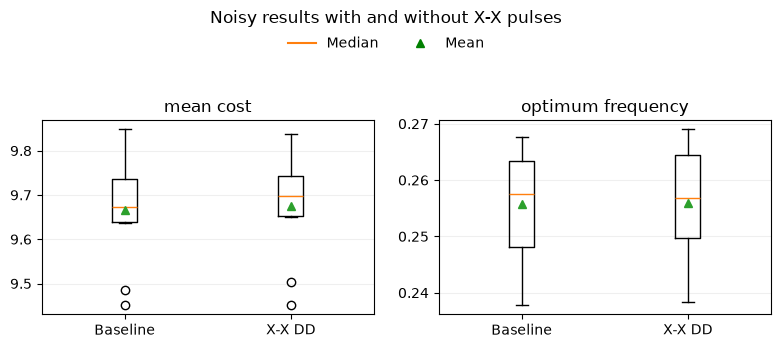

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(8, 3.5))
for ax, metric in zip(axes, ['mean cost', 'optimum frequency']):
    data = [dd_results.loc[dd_results.method == name, metric] for name in circuits]
    ax.boxplot(data, tick_labels=circuits.keys(), showmeans=True)
    ax.set_title(metric)
    ax.grid(axis='y', alpha=.2)
fig.suptitle('Noisy results with and without X-X pulses')
boxplot_legend(fig)
fig.tight_layout(rect=(0, 0, 1, 0.86))
plt.show()

## What did I find?

The saved run added X pulses without changing the scheduled circuit duration or two-qubit gate count. Mean cost and optimum frequency stayed close to the baseline, within the variation between repeats, so I cannot claim a clear benefit from these pulses here.

This uses a historical FakeManilaV2 snapshot and an approximate noise simulation; it is not a real hardware result.